# 开盘区间与日内高低点

回答三个问题（决策 0015）：

1. 全天最高价、最低价一般出现在什么时候？
2. 开盘后 30 / 60 / 90 分钟的区间形成以后，这一天是留在区间里震荡，还是突破走单边？
3. 到那个时刻为止已经知道的信息（区间宽度、跳空、盘前、昨天、最近几天、QQQ）能不能提前判断？

**用法**：改参数单元格，然后 *Run → Run All Cells*。第一次计算全部历史约 3–5 分钟，之后读缓存（`reports/opening_cache/`）。
所有幅度以 ADR（过去 21 天常规时段振幅的中位数）为单位；只用常规时段，数据先经过日内波动报表的清洗。

**走势分类**（第 n 分钟以后）：

| 类型 | 含义 |
|---|---|
| 区间内 | 之后一直没有突破开盘区间：全天高低点都在开盘区间里 |
| 单边突破 | 只突破了一边，而且收盘在突破的那一边之外：趋势日 |
| 突破后收回 | 只突破了一边，但收盘回到区间里：假突破 |
| 双向突破 | 两边都突破了：宽幅震荡 |

In [1]:
# ===== 参数 =====
from trader.analytics import ReportParams

# 跟踪的科技股（杠杆 ETF 和标的走势几乎一样，不重复放）
tickers = ["NVDA", "AMD", "TSLA", "AAPL", "META", "AMZN", "GOOG", "MSFT", "SMH", "SNDK"]
ref = "QQQ"  # 参照证券
start_date = "2024-01-02"
end_date = "2026-10-15"
n = 60  # 主要分析的开盘区间长度（分钟）；第 2 部分同时列出 30 / 60 / 90

params = ReportParams(
    benchmark_tickers=(ref, "SPY"),
    opening_windows_min=(30, 60, 90),
    open_skip_compare=(0, 5, 15, 30, 60, 90),  # 用来算"第 n 分钟以后的可获取波动"
    include_extended_hours=True,  # 盘前振幅要用
)
use_cache = True

In [2]:
import hashlib
import pickle

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

from trader.analytics import build_report, opening
from trader.analytics import report as R
from trader.config import project_dir


def show(fig):
    display(fig)
    plt.close(fig)


pct = "{:.0%}"
key = hashlib.sha1(repr((sorted(tickers), start_date, end_date, params)).encode()).hexdigest()[:12]
cache = project_dir() / "reports" / "opening_cache" / f"{start_date}_{end_date}_{key}.pkl"
if use_cache and cache.exists():
    rep = pickle.loads(cache.read_bytes())
    print(f"读取缓存 {cache.name}")
else:
    rep = build_report(tickers, start_date, end_date, params)
    rep.history = None
    cache.parent.mkdir(parents=True, exist_ok=True)
    cache.write_bytes(pickle.dumps(rep))
    print(f"计算完成，已存缓存 {cache.name}")

d = opening.included_days(rep)  # 个股
q = opening.included_days(rep, [ref])  # 参照证券
print(f"{rep.start} ~ {rep.end}：个股 {len(d)} 个证券日，{ref} {len(q)} 天")

计算完成，已存缓存 2024-01-02_2026-10-15_30962db31221.pkl
2024-01-02 ~ 2026-10-15：个股 6447 个证券日，QQQ 673 天


## 1. 全天最高价、最低价出现在什么时候

柱状图：每 15 分钟一档，最高价（最低价）出现在这一档的天数占比。下表：高低点出现在开盘后 30 / 60 / 90 分钟以内的比例。
`either` = 至少一个已经出现，`both` = 两个都已出现（这一天的高低点在第 n 分钟就定了）。

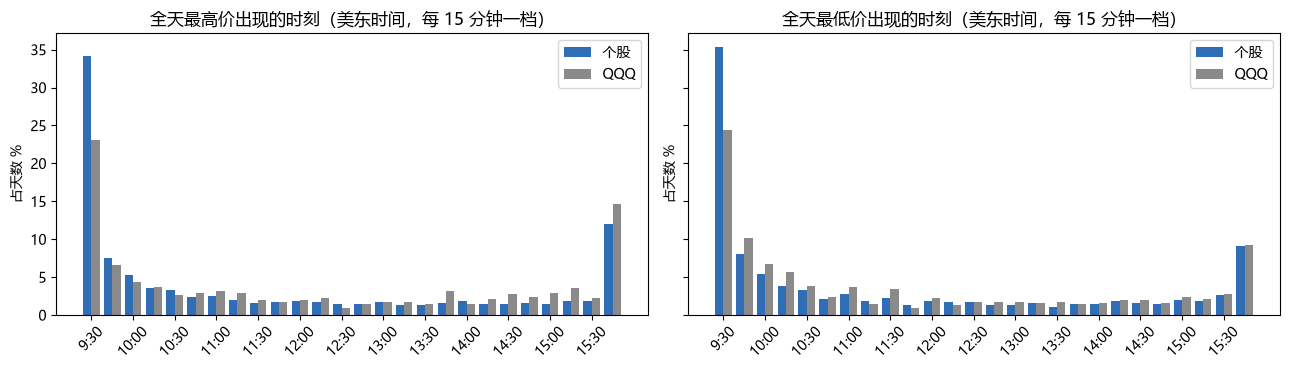

,days,high_30,low_30,either_30,both_30,high_60,low_60,either_60,both_60,high_90,low_90,either_90,both_90
AAPL,673,40%,47%,80%,6%,50%,55%,91%,14%,55%,59%,94%,20%
AMD,673,44%,42%,81%,5%,53%,51%,91%,13%,60%,59%,94%,24%
AMZN,673,41%,44%,81%,5%,49%,51%,90%,11%,55%,55%,93%,17%
GOOG,673,43%,46%,83%,6%,50%,54%,90%,14%,56%,59%,95%,20%
META,673,45%,41%,81%,5%,53%,50%,90%,13%,59%,55%,93%,21%
MSFT,673,41%,45%,79%,6%,50%,53%,90%,13%,55%,57%,93%,19%
NVDA,673,41%,42%,79%,4%,49%,53%,90%,13%,54%,59%,94%,20%
QQQ,673,30%,34%,64%,0%,38%,47%,81%,4%,43%,53%,87%,9%
SMH,673,36%,41%,74%,3%,47%,53%,87%,12%,53%,59%,92%,20%
SNDK,390,43%,47%,84%,6%,53%,58%,93%,17%,57%,62%,94%,24%


In [3]:
show(
    R.fig_extremes_hist({"个股": opening.extremes_histogram(d), ref: opening.extremes_histogram(q)})
)
ex = opening.extremes_summary(pd.concat([d, q]))
display(ex.style.format(pct).format("{:.0f}", subset=["days"]))

## 2. 开盘区间之后的走势分类

每只证券一行，最后一行是全部个股。`高点已出现` / `低点已出现`：之后再没有超过开盘区间的最高 / 最低价；
`额外振幅`：区间之外又走了多少（两边之和，ADR）；`之后可获取`：第 n 分钟以后开始的摆动的可获取波动（ADR，日内波动报表口径）。

In [4]:
fmt_t = {c: pct for c in (*opening.TYPES, "高点已出现", "低点已出现")}
fmt_t |= {"days": "{:.0f}", "额外振幅": "{:.2f}", "之后可获取": "{:.2f}"}
for w in params.opening_windows_min:
    display(Markdown(f"**开盘 {w} 分钟区间**（{ref} 单独一行在最后）"))
    t = opening.type_shares(opening.day_outcomes(d, w))
    tq = opening.type_shares(opening.day_outcomes(q, w), None).rename(index={"全部": ref})
    display(pd.concat([t, tq]).style.format(fmt_t))

**开盘 30 分钟区间**（QQQ 单独一行在最后）

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
AAPL,673,6%,43%,31%,20%,40%,47%,0.47,0.29
AMD,673,5%,46%,29%,19%,44%,42%,0.45,0.27
AMZN,673,5%,47%,29%,19%,41%,44%,0.46,0.24
GOOG,673,6%,47%,30%,17%,43%,46%,0.45,0.27
META,673,5%,46%,29%,19%,45%,41%,0.45,0.26
MSFT,673,6%,45%,28%,21%,41%,45%,0.45,0.23
NVDA,673,4%,48%,27%,21%,41%,42%,0.50,0.31
SMH,673,3%,45%,25%,26%,36%,41%,0.54,0.34
SNDK,390,6%,45%,33%,16%,43%,47%,0.45,0.33
TSLA,673,4%,48%,28%,20%,43%,41%,0.47,0.25


**开盘 60 分钟区间**（QQQ 单独一行在最后）

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
AAPL,673,14%,40%,38%,9%,50%,55%,0.36,0.21
AMD,673,13%,41%,37%,9%,53%,51%,0.32,0.18
AMZN,673,11%,42%,37%,10%,49%,51%,0.35,0.17
GOOG,673,14%,41%,36%,10%,50%,54%,0.34,0.19
META,673,13%,41%,35%,10%,53%,50%,0.33,0.17
MSFT,673,13%,43%,34%,10%,50%,53%,0.34,0.16
NVDA,673,13%,45%,32%,10%,49%,53%,0.37,0.22
SMH,673,12%,42%,33%,13%,47%,53%,0.40,0.25
SNDK,390,17%,41%,35%,7%,53%,58%,0.33,0.24
TSLA,673,12%,43%,35%,10%,52%,51%,0.34,0.17


**开盘 90 分钟区间**（QQQ 单独一行在最后）

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
AAPL,673,20%,35%,40%,6%,55%,59%,0.30,0.17
AMD,673,24%,35%,35%,6%,60%,59%,0.25,0.13
AMZN,673,17%,41%,36%,7%,55%,55%,0.28,0.12
GOOG,673,20%,38%,37%,5%,56%,59%,0.28,0.13
META,673,21%,36%,35%,7%,59%,55%,0.26,0.13
MSFT,673,19%,39%,35%,7%,55%,57%,0.28,0.12
NVDA,673,20%,39%,35%,6%,54%,59%,0.29,0.16
SMH,673,20%,39%,33%,8%,53%,59%,0.31,0.18
SNDK,390,24%,36%,34%,6%,57%,62%,0.26,0.18
TSLA,673,21%,39%,36%,5%,58%,58%,0.27,0.12


## 3. 第 n 分钟时能不能判断

先看总表：每个特征按三等分分档后，各项比例"最高一档 − 最低一档"的差。**差越大，这个特征越有用；接近 0 就是没有参考价值。**
`之后可获取` 一列是 ADR 单位，其余是百分点。下面再逐个列出分档明细。

In [5]:
out = opening.day_outcomes(d, n)
feats = opening.features(rep.daily, n, ref=ref)
fs = opening.factor_summary(out, feats)
display(fs.style.format("{:.2f}").background_gradient(cmap="Greens", axis=None))

,区间内,单边突破,突破后收回,双向突破,高点已出现,之后可获取
or_width（开盘区间宽度）,0.15,0.05,0.05,0.15,0.16,0.23
or_pos（第 n 分钟价格在区间里的位置）,0.05,0.05,0.04,0.02,0.63,0.03
gap（跳空）,0.02,0.01,0.01,0.01,0.02,0.09
pm_range（盘前振幅）,0.01,0.03,0.03,0.01,0.03,0.23
open_vs_prev（开盘在昨天区间的位置）,0.03,0.03,0.02,0.01,0.03,0.05
prev_range（昨天振幅）,0.03,0.04,0.00,0.01,0.03,0.16
prev_body（昨天实体比例（单边程度））,0.01,0.03,0.02,0.00,0.01,0.04
vol5（最近 5 天平均振幅）,0.00,0.03,0.02,0.03,0.02,0.19
trend5（最近 5 天涨跌）,0.03,0.03,0.03,0.02,0.06,0.07
ref_or_width（QQQ 开盘区间宽度）,0.04,0.02,0.02,0.05,0.05,0.16


In [6]:
bins = {
    "or_width": 4,
    "or_pos": [-0.01, 0.2, 0.8, 1.01],
    "gap": [-99, -0.5, -0.15, 0.15, 0.5, 99],
    "pm_range": 4,
    "open_vs_prev": [-99, 0, 0.5, 1, 99],
    "prev_range": 3,
    "prev_body": 3,
    "vol5": 3,
    "trend5": [-99, -1, -0.3, 0.3, 1, 99],
    "ref_or_width": 3,
    "same_dir": 3,
}
for name, b in bins.items():
    display(Markdown(f"**{name}：{opening.FEATURE_NOTES[name]}**"))
    display(opening.conditional(out, feats, name, b).style.format(fmt_t))

**or_width：开盘区间宽度**

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
or_width,,,,,,,,,
"(0.221, 0.542]",1612,5%,43%,32%,19%,42%,44%,0.34,0.08
"(0.542, 0.706]",1612,10%,46%,34%,11%,48%,51%,0.35,0.14
"(0.706, 0.926]",1611,14%,42%,37%,7%,51%,56%,0.34,0.19
"(0.926, 4.15]",1612,23%,37%,37%,2%,61%,60%,0.37,0.36
全部,6447,13%,42%,35%,10%,50%,53%,0.35,0.19


**or_pos：第 n 分钟价格在区间里的位置**

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
or_pos,,,,,,,,,
"(-0.01, 0.2]",1362,8%,44%,39%,9%,85%,14%,0.41,0.21
"(0.2, 0.8]",3603,17%,39%,33%,11%,53%,53%,0.32,0.19
"(0.8, 1.01]",1482,8%,47%,37%,8%,13%,86%,0.37,0.18
全部,6447,13%,42%,35%,10%,50%,53%,0.35,0.19


**gap：跳空**

...

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
trend5,,,,,,,,,
"(-99.0, -1.0]",1674,11%,43%,35%,11%,48%,53%,0.38,0.24
"(-1.0, -0.3]",803,14%,43%,35%,9%,51%,55%,0.33,0.15
"(-0.3, 0.3]",780,13%,42%,36%,9%,49%,56%,0.31,0.14
"(0.3, 1.0]",914,12%,42%,37%,9%,50%,53%,0.32,0.15
"(1.0, 99.0]",2276,14%,41%,34%,10%,53%,51%,0.35,0.21
全部,6447,13%,42%,35%,10%,50%,53%,0.35,0.19


**ref_or_width：QQQ 开盘区间宽度**

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
ref_or_width,,,,,,,,,
"(0.175, 0.496]",2157,11%,41%,35%,13%,47%,50%,0.32,0.13
"(0.496, 0.717]",2141,14%,43%,34%,9%,52%,54%,0.34,0.16
"(0.717, 4.137]",2149,14%,42%,36%,8%,52%,54%,0.38,0.29
全部,6447,13%,42%,35%,10%,50%,53%,0.35,0.19


**same_dir：开盘以来和 QQQ 同向**

,days,区间内,单边突破,突破后收回,双向突破,高点已出现,低点已出现,额外振幅,之后可获取
same_dir,,,,,,,,,
否,1926,14%,40%,35%,10%,51%,53%,0.32,0.17
是,4521,12%,43%,35%,10%,50%,52%,0.36,0.20
全部,6447,13%,42%,35%,10%,50%,53%,0.35,0.19


## 4. 和 QQQ 的关系

**同步程度**：全天同涨同跌的比例；最高价（最低价）出现时刻相差不超过 15 分钟的比例。

**突破时 QQQ 的状态**：个股第一次突破开盘区间的那一刻，QQQ 是已经同向突破、还没突破、还是已经反向突破；
`突破成功` = 收盘在突破方向的区间之外；`反向也突破` = 之后另一边也被突破；`突破方向额外幅度` = 突破方向上又走了多少（ADR）。

In [7]:
sync = opening.ref_sync(opening.included_days(rep, [*rep.tickers, ref]), ref=ref)
display(sync.style.format(pct))
al = opening.ref_alignment(out, rep.daily, n, ref=ref)
display(
    al.style.format(
        {
            "次数": "{:.0f}",
            "占比": pct,
            "突破成功": pct,
            "反向也突破": pct,
            "突破方向额外幅度": "{:.2f}",
        }
    )
)

,同涨同跌,高点同时,低点同时
AAPL,66%,30%,36%
AMD,73%,37%,48%
AMZN,72%,38%,47%
GOOG,69%,35%,41%
META,72%,35%,44%
MSFT,73%,39%,43%
NVDA,77%,44%,54%
SMH,86%,56%,66%
SNDK,67%,29%,37%
TSLA,68%,33%,42%


,次数,占比,突破成功,反向也突破,突破方向额外幅度
已同向突破,2794,50%,49%,11%,0.36
还没突破,2127,38%,50%,12%,0.39
已反向突破,687,12%,44%,11%,0.30
全部,5608,100%,49%,11%,0.36


## 5. 导出

`reports/opening_<起>_<止>_n<分钟>/`：day_outcomes.csv（每天的分类）、features.csv（每天的特征）、factor_summary.csv。

In [8]:
outdir = project_dir() / "reports" / f"opening_{rep.start}_{rep.end}_n{n}"
outdir.mkdir(parents=True, exist_ok=True)
out.to_csv(outdir / "day_outcomes.csv", index=False, encoding="utf-8-sig")
feats.to_csv(outdir / "features.csv", index=False, encoding="utf-8-sig")
fs.to_csv(outdir / "factor_summary.csv", encoding="utf-8-sig")
print(outdir)

C:\My_Works\DayTrader\DayTrader\reports\opening_2024-01-02_2026-10-15_n60
